# Bagging learning

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


C:\Users\Alok Kumar\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
df=pd.read_csv("Iris.csv")

In [4]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [5]:

df = df.iloc[:,1:]

In [6]:
df.head(
)

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [7]:

from sklearn.preprocessing import LabelEncoder

In [8]:
encoder = LabelEncoder()

In [9]:

df['Species'] = encoder.fit_transform(df['Species'])

In [10]:

df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [11]:
df = df[df['Species'] != 0][['SepalWidthCm','PetalLengthCm','Species']]


In [12]:
df.head()


,SepalWidthCm,PetalLengthCm,Species
50,3.2,4.7,1
51,3.2,4.5,1
52,3.1,4.9,1
53,2.3,4.0,1
54,2.8,4.6,1


In [13]:
import seaborn as sns
import matplotlib.pyplot as plt


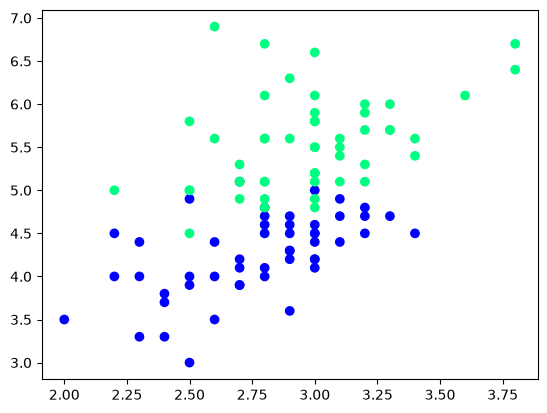

In [14]:
plt.scatter(df['SepalWidthCm'],df['PetalLengthCm'],c=df['Species'],cmap='winter')


In [15]:
df_train = df.iloc[:60,:].sample(10)
df_train

,SepalWidthCm,PetalLengthCm,Species
72,2.5,4.9,1
84,3.0,4.5,1
108,2.5,5.8,2
71,2.8,4.0,1
73,2.8,4.7,1
98,2.5,3.0,1
63,2.9,4.7,1
106,2.5,4.5,2
62,2.2,4.0,1
87,2.3,4.4,1


In [16]:
# Taking only 10 rows for training
df = df.sample(100)
df_train = df.iloc[:60,:].sample(10)
df_val = df.iloc[60:80,:].sample(5)
df_test = df.iloc[80:,:].sample(5)


In [17]:

df_train

,SepalWidthCm,PetalLengthCm,Species
122,2.8,6.7,2
94,2.7,4.2,1
81,2.4,3.7,1
54,2.8,4.6,1
55,2.8,4.5,1
96,2.9,4.2,1
80,2.4,3.8,1
136,3.4,5.6,2
137,3.1,5.5,2
92,2.6,4.0,1


In [18]:

df_val

,SepalWidthCm,PetalLengthCm,Species
100,3.3,6.0,2
50,3.2,4.7,1
101,2.7,5.1,2
125,3.2,6.0,2
131,3.8,6.4,2


In [19]:
df_test

,SepalWidthCm,PetalLengthCm,Species
138,3.0,4.8,2
115,3.2,5.3,2
142,2.7,5.1,2
51,3.2,4.5,1
76,2.8,4.8,1


In [20]:
X_test = df_val.iloc[:,0:2].values
y_test = df_val.iloc[:,-1].values

In [21]:
y_test

array([2, 1, 2, 2, 2])

#  Bagging 

In [22]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)

X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

df_bag

,SepalWidthCm,PetalLengthCm,Species
122,2.8,6.7,2
137,3.1,5.5,2
81,2.4,3.7,1
122,2.8,6.7,2
137,3.1,5.5,2
81,2.4,3.7,1
136,3.4,5.6,2
80,2.4,3.8,1


In [23]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from mlxtend.plotting import plot_decision_regions
from sklearn.metrics import accuracy_score

In [24]:
dt_bag1 = DecisionTreeClassifier()

In [26]:
def evaluate(clf,X,y):
    clf.fit(X,y)
    plot_tree(clf)
    plt.show()
    plot_decision_regions(X.values, y.values, clf=clf, legend=2)
    y_pred = clf.predict(X_test)
    print(accuracy_score(y_test,y_pred))

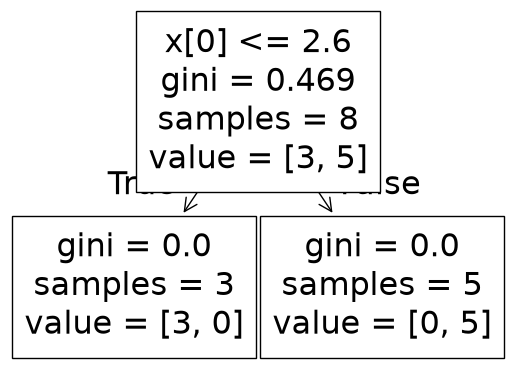

C:\Users\Alok Kumar\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\Alok Kumar\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


0.8


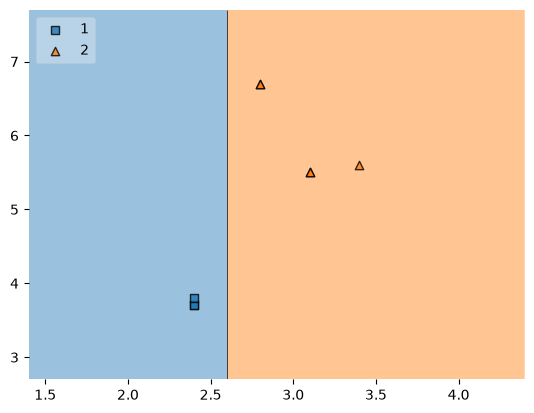

In [27]:
evaluate(dt_bag1,X,y)

In [28]:

# Data for Tree 1
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,SepalWidthCm,PetalLengthCm,Species
80,2.4,3.8,1
80,2.4,3.8,1
81,2.4,3.7,1
122,2.8,6.7,2
136,3.4,5.6,2
96,2.9,4.2,1
94,2.7,4.2,1
137,3.1,5.5,2


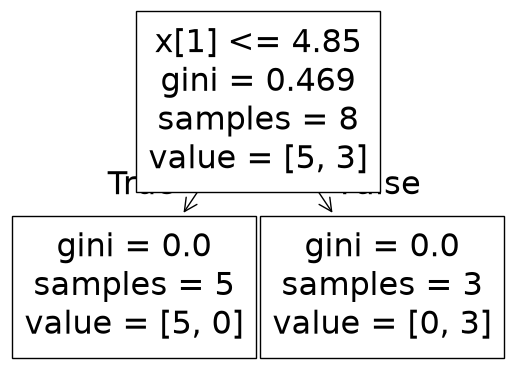

1.0


C:\Users\Alok Kumar\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\Alok Kumar\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


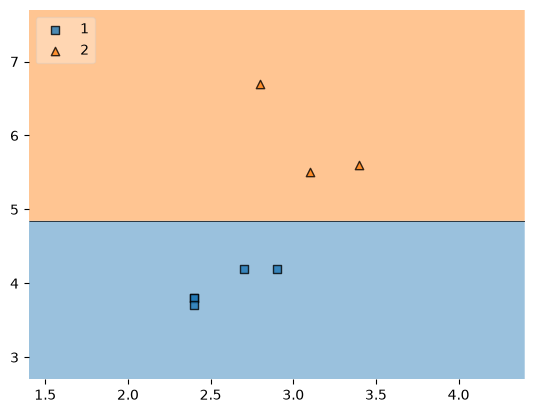

In [29]:
dt_bag2 = DecisionTreeClassifier()
evaluate(dt_bag2,X,y)

In [30]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,SepalWidthCm,PetalLengthCm,Species
81,2.4,3.7,1
81,2.4,3.7,1
96,2.9,4.2,1
137,3.1,5.5,2
96,2.9,4.2,1
136,3.4,5.6,2
122,2.8,6.7,2
94,2.7,4.2,1


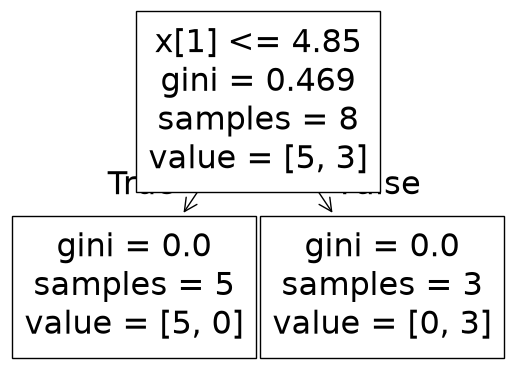

1.0


C:\Users\Alok Kumar\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\Alok Kumar\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


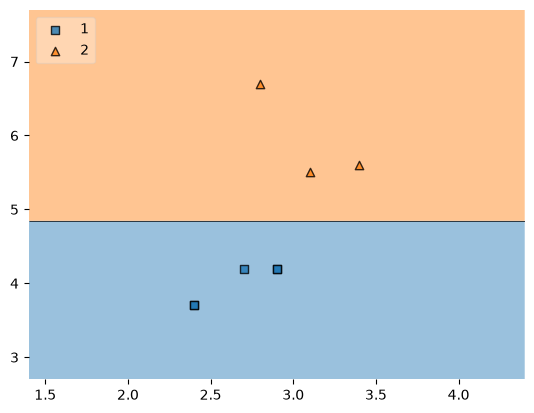

In [31]:
dt_bag3 = DecisionTreeClassifier()
evaluate(dt_bag3,X,y)

In [32]:

df_test


,SepalWidthCm,PetalLengthCm,Species
138,3.0,4.8,2
115,3.2,5.3,2
142,2.7,5.1,2
51,3.2,4.5,1
76,2.8,4.8,1


# predict

In [33]:

print("Predictor 1",dt_bag1.predict(np.array([2.2,5.0]).reshape(1,2)))
print("Predictor 2",dt_bag2.predict(np.array([2.2,5.0]).reshape(1,2)))
print("Predictor 3",dt_bag3.predict(np.array([2.2,5.0]).reshape(1,2)))

Predictor 1 [1]
Predictor 2 [2]
Predictor 3 [2]


C:\Users\Alok Kumar\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\Alok Kumar\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\Alok Kumar\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


#  Pasting

In [34]:
# Row sampling without replacement
df_train

,SepalWidthCm,PetalLengthCm,Species
122,2.8,6.7,2
94,2.7,4.2,1
81,2.4,3.7,1
54,2.8,4.6,1
55,2.8,4.5,1
96,2.9,4.2,1
80,2.4,3.8,1
136,3.4,5.6,2
137,3.1,5.5,2
92,2.6,4.0,1


In [35]:

df_train.sample(8)

,SepalWidthCm,PetalLengthCm,Species
96,2.9,4.2,1
136,3.4,5.6,2
122,2.8,6.7,2
55,2.8,4.5,1
54,2.8,4.6,1
80,2.4,3.8,1
137,3.1,5.5,2
81,2.4,3.7,1


# Random Subspaces

In [36]:
df1=pd.read_csv("Iris.csv")

In [37]:
df1=df1.sample(10)

In [38]:
df1

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
58,59,6.6,2.9,4.6,1.3,Iris-versicolor
41,42,4.5,2.3,1.3,0.3,Iris-setosa
97,98,6.2,2.9,4.3,1.3,Iris-versicolor
57,58,4.9,2.4,3.3,1.0,Iris-versicolor
5,6,5.4,3.9,1.7,0.4,Iris-setosa
95,96,5.7,3.0,4.2,1.2,Iris-versicolor
2,3,4.7,3.2,1.3,0.2,Iris-setosa
11,12,4.8,3.4,1.6,0.2,Iris-setosa
23,24,5.1,3.3,1.7,0.5,Iris-setosa
115,116,6.4,3.2,5.3,2.3,Iris-virginica


In [39]:
df1.sample(2,replace=True,axis=1)

,Id,PetalWidthCm
58,59,1.3
41,42,0.3
97,98,1.3
57,58,1.0
5,6,0.4
95,96,1.2
2,3,0.2
11,12,0.2
23,24,0.5
115,116,2.3


# Random patches

In [40]:
df1

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
58,59,6.6,2.9,4.6,1.3,Iris-versicolor
41,42,4.5,2.3,1.3,0.3,Iris-setosa
97,98,6.2,2.9,4.3,1.3,Iris-versicolor
57,58,4.9,2.4,3.3,1.0,Iris-versicolor
5,6,5.4,3.9,1.7,0.4,Iris-setosa
95,96,5.7,3.0,4.2,1.2,Iris-versicolor
2,3,4.7,3.2,1.3,0.2,Iris-setosa
11,12,4.8,3.4,1.6,0.2,Iris-setosa
23,24,5.1,3.3,1.7,0.5,Iris-setosa
115,116,6.4,3.2,5.3,2.3,Iris-virginica


In [41]:
df1.sample(8,replace=True).sample(2,replace=True,axis=1)


,PetalWidthCm,SepalLengthCm
2,0.2,4.7
58,1.3,6.6
23,0.5,5.1
5,0.4,5.4
57,1.0,4.9
57,1.0,4.9
5,0.4,5.4
23,0.5,5.1
